<a href="https://colab.research.google.com/github/selam-spec/Machine-maintenance-markov_Chains/blob/main/Copy_of_Application_of_Random_Processes_In_Manufacturing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# 0 = Working, 1 = Degraded, 2 = Broken, 3 = Repair
states = ["Working", "Degraded", "Broken", "Repair"]

# Policy B: preventive. Degraded machines are usually serviced before they fail
P_Preventative = [
    [0.95, 0.05, 0,   0  ],   # from Working
    [0,    0.3,  0.1, 0.6],   # from Degraded
    [0,    0,    0.1, 0.9],   # from Broken
    [0.9,  0,    0,   0.1],   # from Repair
]

# Policy A: reactive. Degraded machines run until they break; breakdown repairs take longer
P_reactive = [
    [0.95, 0.05, 0,   0  ],   # from Working
    [0,    0.3,  0.7, 0  ],   # from Degraded
    [0,    0,    0.1, 0.9],   # from Broken
    [0.5,  0,    0,   0.5],   # from Repair
]

In [ ]:
def simulate(P, start, n):
    path = [start]
    current = start
    for i in range(n):
        nxt = random.choices(range(len(P)), weights=P[current])[0]
        path.append(nxt)
        current = nxt
    return path

path = simulate(P_Preventative, 0, 20)
print([states[s] for s in path])

['Working', 'Working', 'Working', 'Working', 'Working', 'Working', 'Working', 'Working', 'Working', 'Working', 'Working', 'Working', 'Working', 'Working', 'Working', 'Working', 'Working', 'Working', 'Working', 'Working', 'Working']


In [ ]:
def stationary(P):
    M = np.array(P).T
    eigenvalues, eigenvectors = np.linalg.eig(M)
    position = np.argmin(np.abs(eigenvalues - 1))
    V = eigenvectors[:, position]
    return np.real(V / V.sum())

pi = stationary(P_Preventative)
print(pi)
print(np.allclose(pi @ np.array(P_Preventative), pi))   # check: pi P = pi

[0.88111888 0.06293706 0.00699301 0.04895105]
True


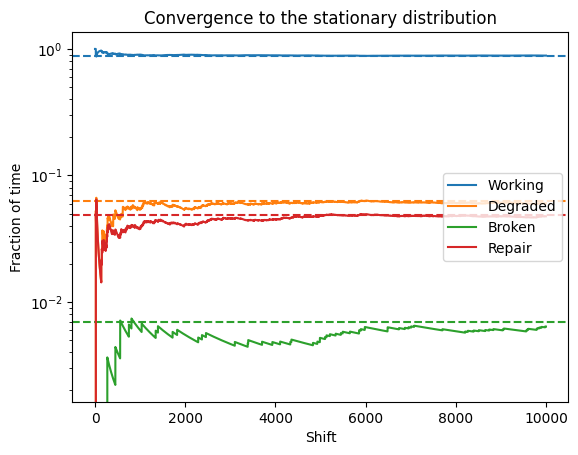

In [ ]:
path = simulate(P_Preventative, 0, 10000)
path_arr = np.array(path)
no_of_shifts = np.arange(1, len(path) + 1)

for s in range(4):
    running_fraction = np.cumsum(path_arr == s) / no_of_shifts
    plt.plot(running_fraction, label=states[s], color=f"C{s}")
    plt.axhline(pi[s], linestyle="--", color=f"C{s}")

plt.yscale("log")
plt.title("Convergence to the stationary distribution")
plt.xlabel("Shift")
plt.ylabel("Fraction of time")
plt.legend(loc="center right")
plt.show()

Preventive availability: 0.881
Reactive availability:   0.815


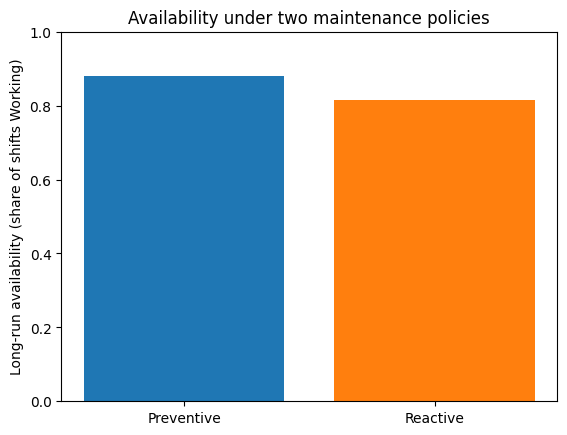

In [ ]:
pi_prev = stationary(P_Preventative)
pi_reac = stationary(P_reactive)

print("Preventive availability:", round(pi_prev[0], 3))
print("Reactive availability:  ", round(pi_reac[0], 3))

plt.bar(["Preventive", "Reactive"], [pi_prev[0], pi_reac[0]], color=["C0", "C1"])
plt.ylabel("Long-run availability (share of shifts Working)")
plt.title("Availability under two maintenance policies")
plt.ylim(0, 1)
plt.show()

Modelling machine availability with a Markov chain

The question

A production machine is not just simply on or off, as it wears gradually, sometimes fails and then has to wait for and go through repair which means the share of time it is actually available to produce isn't obvious from any single shift.

This project models that process as a discrete-time Markov chain to ask two questions: what share of the time is the machine available in the long run, and what does servicing machines once they start to wear actually improve that compared with waiting for them to break?

The model

Each shift, the machine is in one of four states: Working, Degraded (still running but deteriorated), Broken, or Under Repair. I set each diagonal entry of the transition matrix from an assumed average duration in that state, since time spent in a state is geometrically distributed, so an average stay of d shifts corresponds to a staying probability of p = 1 − 1/d.

Under the preventive policy:

| State | Average stay | Then moves to | What it represents |
|---|---|---|---|
| Working | ~20 shifts | always Degraded | Machines wear gradually rather than failing without warning |
| Degraded | ~1.4 shifts | Repair 6 in 7 times, Broken 1 in 7 | Wear is usually spotted and serviced before it becomes a failure |
| Broken | ~1.1 shifts | always Repair | A technician starts almost immediately |
| Repair | ~1.1 shifts | always Working | Routine servicing is quick and always succeeds |

Under the reactive policy, nobody services degraded machines, so every episode of wear ends in a breakdown, and I assumed breakdown repairs take longer (around 2 shifts), as they are typically bigger jobs than routine servicing.

Results

Solving πP = π gives the long-run share of time in each state:

| Policy | Working | Degraded | Broken | Repair |
|---|---|---|---|---|
| Preventive | 88.1% | 6.3% | 0.7% | 4.9% |
| Reactive | 81.5% | 5.8% | 4.5% | 8.2% |

I also simulated 10,000 shifts under the preventive policy and tracked the running share of time in each state. Each line settles onto its theoretical value, which is the ergodic theorem in practice and shows that the simulation and algebra agree.

What It Shows:

Preventive maintenance raises availability by about 6.6 percentage points, and the reason is not that machines last longer between problems, since in both cases a machine works for around 20 shifts before wear sets in.

The difference lies entirely in what happens next: under the preventive policy six in seven episodes of wear are caught and fixed with a quick service, which costs around 2.7 shifts of downtime per episode, whereas under the reactive policy every episode ends in a breakdown followed by a longer repair, costing around 4.5 shifts.

The result also holds if breakdown repairs are assumed to take no longer than servicing, with availability under the reactive policy still lower at around 84.6%, because every breakdown adds a wait before repair can begin, which suggests the conclusion is reasonably robust to that assumption.

Limitations

The model assumes the Markov property, which means the machine has no memory, whereas real machines age and become more likely to fail over time, which an age-dependent or semi-Markov model would capture better.

The transition probabilities are assumed rather than estimated, so the natural next step would be to fit them to real maintenance logs.

Degraded shifts are counted as unavailable, although in practice a degraded machine may still produce at a reduced rate.

Availability ignores cost, and preventive servicing uses technician time and parts, so a full comparison would attach a cost to each state and compare the long-run cost per shift, π · c, under each policy.

Rare states converge slowly in simulation, as breakdowns are exactly the rare events that are hardest to estimate from limited data.

Next steps

Adding a cost to each state to compare policies on cost per shift rather than availability alone, and finding the point at which preventive servicing stops being worth it, for example how expensive it would have to be before the reactive policy becomes cheaper.

